In [ ]:
# Cell 2: Load actual CSV dataset
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Reading your uploaded Kaggle file
df = pd.read_csv('House Price Prediction Dataset.csv')

# Display first 5 rows of actual data
df.head()

,Id,Area,Bedrooms,Bathrooms,Floors,YearBuilt,Location,Condition,Garage,Price
0,1,1360,5,4,3,1970,Downtown,Excellent,No,149919
1,2,4272,5,4,3,1958,Downtown,Excellent,No,424998
2,3,3592,2,2,3,1938,Downtown,Good,No,266746
3,4,966,4,2,2,1902,Suburban,Fair,Yes,244020
4,5,4926,1,4,2,1975,Downtown,Fair,Yes,636056


--- 1. NULL VALUES CHECK ---
Id           0
Area         0
Bedrooms     0
Bathrooms    0
Floors       0
YearBuilt    0
Location     0
Condition    0
Garage       0
Price        0
dtype: int64


--- 2. DESCRIPTIVE STATISTICS ---
                Id         Area     Bedrooms   Bathrooms       Floors  \
count  2000.000000  2000.000000  2000.000000  2000.00000  2000.000000   
mean   1000.500000  2786.209500     3.003500     2.55250     1.993500   
std     577.494589  1295.146799     1.424606     1.10899     0.809188   
min       1.000000   501.000000     1.000000     1.00000     1.000000   
25%     500.750000  1653.000000     2.000000     2.00000     1.000000   
50%    1000.500000  2833.000000     3.000000     3.00000     2.000000   
75%    1500.250000  3887.500000     4.000000     4.00000     3.000000   
max    2000.000000  4999.000000     5.000000     4.00000     3.000000   

         YearBuilt          Price  
count  2000.000000    2000.000000  
mean   1961.446000  537676.855000  
std   

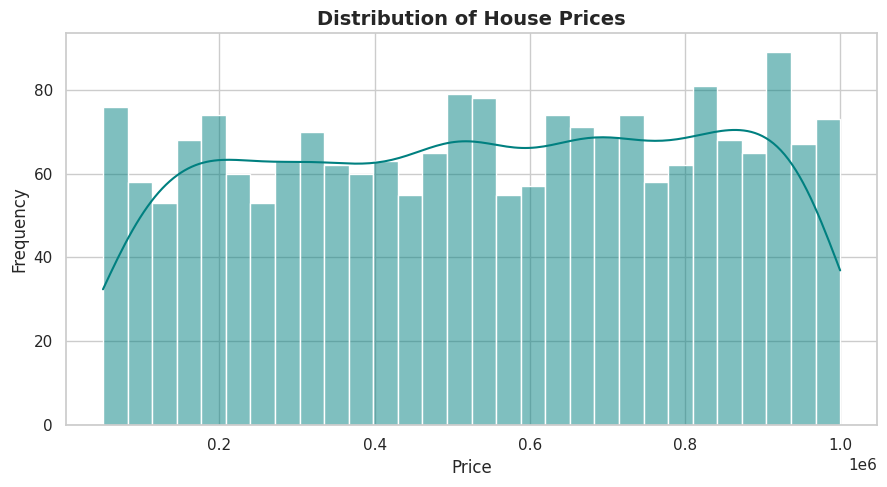

In [ ]:
# ==========================================
# STEP 3: Handling Missing Values & Encoding
# ==========================================
# Drop 'Id' column as it is just an index
df_clean = df.drop(columns=['Id'])

# Impute missing values with median if any exist
num_cols = ['Area', 'Bedrooms', 'Bathrooms', 'Floors', 'YearBuilt']
for col in num_cols:
    if df_clean[col].isnull().sum() > 0:
        df_clean[col] = df_clean[col].fillna(df_clean[col].median())

# One-Hot Encoding for categorical features (Location, Condition, Garage)
df_encoded = pd.get_dummies(df_clean, columns=['Location', 'Condition', 'Garage'], drop_first=True, dtype=int)

print("Data cleaning & encoding complete!")
print("Encoded Columns:", list(df_encoded.columns))
df_encoded.head()

Data cleaning & encoding complete!
Encoded Columns: ['Area', 'Bedrooms', 'Bathrooms', 'Floors', 'YearBuilt', 'Price', 'Location_Rural', 'Location_Suburban', 'Location_Urban', 'Condition_Fair', 'Condition_Good', 'Condition_Poor', 'Garage_Yes']


,Area,Bedrooms,Bathrooms,Floors,YearBuilt,Price,Location_Rural,Location_Suburban,Location_Urban,Condition_Fair,Condition_Good,Condition_Poor,Garage_Yes
0,1360,5,4,3,1970,149919,0,0,0,0,0,0,0
1,4272,5,4,3,1958,424998,0,0,0,0,0,0,0
2,3592,2,2,3,1938,266746,0,0,0,0,1,0,0
3,966,4,2,2,1902,244020,0,1,0,1,0,0,1
4,4926,1,4,2,1975,636056,0,0,0,1,0,0,1


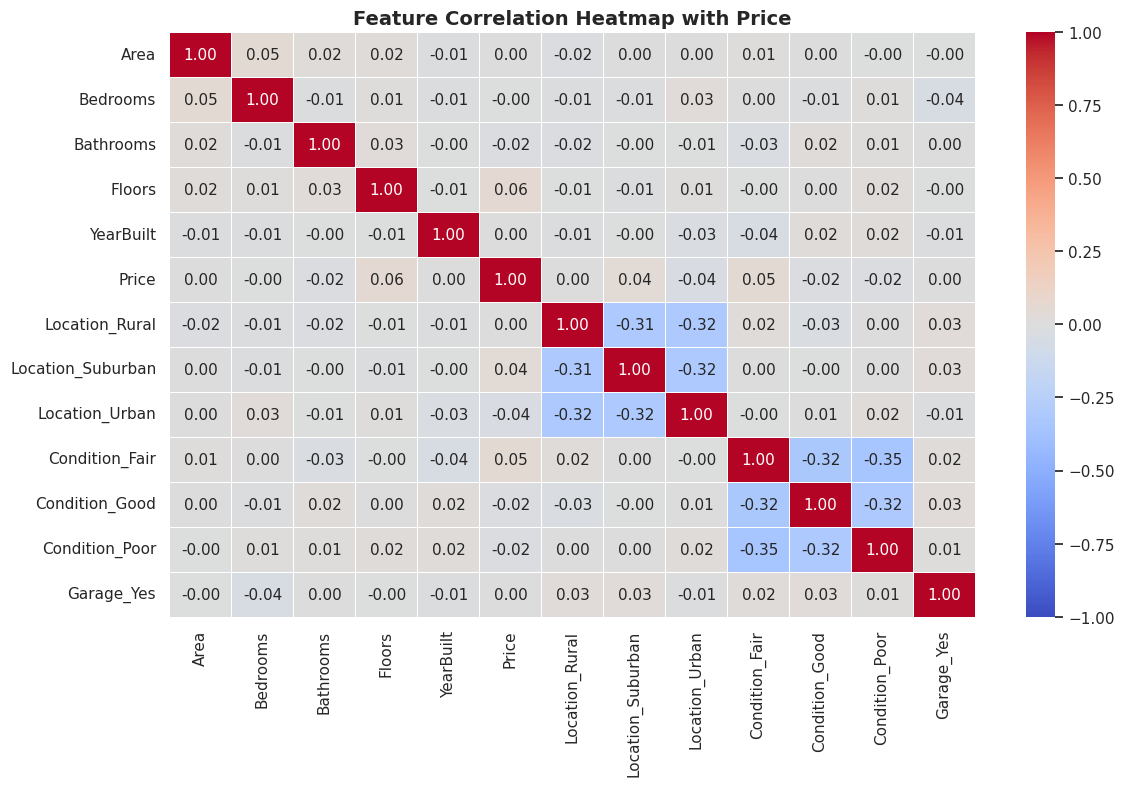

--- Features Correlated with Price ---
Price                1.000000
Floors               0.055890
Condition_Fair       0.049218
Location_Suburban    0.040303
YearBuilt            0.004845
Garage_Yes           0.002842
Location_Rural       0.001890
Area                 0.001542
Bedrooms            -0.003471
Bathrooms           -0.015737
Condition_Good      -0.017179
Condition_Poor      -0.018437
Location_Urban      -0.038312
Name: Price, dtype: float64


In [ ]:
# ==========================================
# STEP 4: Correlation Heatmap
# ==========================================
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(12, 8))
corr_matrix = df_encoded.corr()

# Draw heatmap
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5, vmin=-1, vmax=1)
plt.title('Feature Correlation Heatmap with Price', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

print("--- Features Correlated with Price ---")
print(corr_matrix['Price'].sort_values(ascending=False))

In [ ]:
# ==========================================
# STEP 5: Train / Test Split (80/20)
# ==========================================
from sklearn.model_selection import train_test_split

# Define Features (X) and Target (y)
X = df_encoded.drop(columns=['Price'])
y = df_encoded['Price']

# 80% Training, 20% Testing split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42)

print(f"Training set size: {X_train.shape[0]} samples")
print(f"Testing set size : {X_test.shape[0]} samples")

Training set size: 1600 samples
Testing set size : 400 samples


In [ ]:
# ==========================================
# STEP 6: Train Linear Regression Model
# ==========================================
from sklearn.linear_model import LinearRegression

# Model initialize aur train karna
lr_model = LinearRegression()
lr_model.fit(X_train, y_train)

print("Linear Regression Model successfully trained!")
print(f"Model Intercept (Bias): {lr_model.intercept_:,.2f}")

Linear Regression Model successfully trained!
Model Intercept (Bias): 278,520.53


In [ ]:
# ==========================================
# STEP 7: Performance Evaluation
# ==========================================
from sklearn.metrics import mean_squared_error, r2_score
import numpy as np

# Test set par predictions
y_pred = lr_model.predict(X_test)

# Metrics calculation
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("--- MODEL EVALUATION METRICS ---")
print(f"Mean Squared Error (MSE) : {mse:,.2f}")
print(f"Root Mean Squared Error (RMSE): {rmse:,.2f}")
print(f"R² Score (Variance Explained) : {r2:.4f}")

--- MODEL EVALUATION METRICS ---
Mean Squared Error (MSE) : 78,321,466,146.03
Root Mean Squared Error (RMSE): 279,859.73
R² Score (Variance Explained) : -0.0067


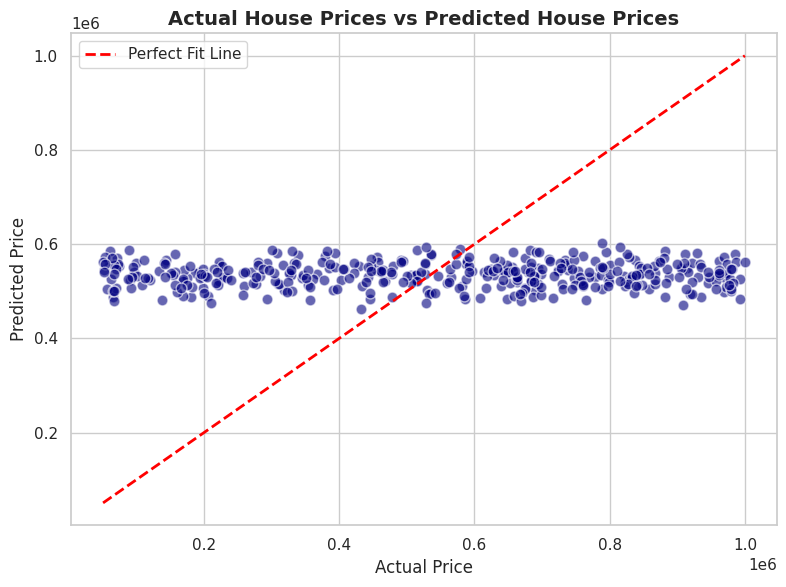

In [ ]:
# ==========================================
# STEP 8: Scatter Plot
# ==========================================
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))
plt.scatter(y_test, y_pred, alpha=0.6, color='navy', edgecolors='w', s=60)

# 45-degree reference line
min_val = min(y_test.min(), y_pred.min())
max_val = max(y_test.max(), y_pred.max())
plt.plot([min_val, max_val], [min_val, max_val], color='red', linestyle='--', linewidth=2, label='Perfect Fit Line')

plt.title('Actual House Prices vs Predicted House Prices', fontsize=14, fontweight='bold')
plt.xlabel('Actual Price')
plt.ylabel('Predicted Price')
plt.legend()
plt.tight_layout()
plt.show()

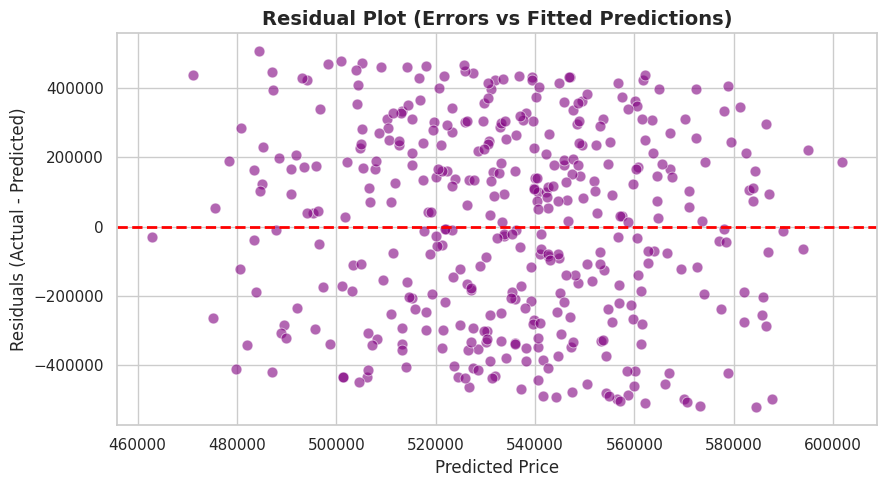

In [ ]:
# ==========================================
# STEP 9: Residual Analysis
# ==========================================
residuals = y_test - y_pred

plt.figure(figsize=(9, 5))
sns.scatterplot(x=y_pred, y=residuals, alpha=0.6, color='purple', edgecolors='w', s=60)
plt.axhline(y=0, color='red', linestyle='--', linewidth=2)

plt.title('Residual Plot (Errors vs Fitted Predictions)', fontsize=14, fontweight='bold')
plt.xlabel('Predicted Price')
plt.ylabel('Residuals (Actual - Predicted)')
plt.tight_layout()
plt.show()

In [ ]:
# ==========================================
# STEP 10: Feature Coefficient Analysis (Fixed)
# ==========================================
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Flatten coefficients to ensure 1D array
coef_values = lr_model.coef_.ravel() if hasattr(lr_model.coef_, 'ravel') else lr_model.coef_

coef_df = pd.DataFrame({
    'Feature': X.columns,
    'Coefficient': coef_values
}).sort_values(by='Coefficient', ascending=False)

print("--- FEATURE COEFFICIENTS TABLE ---")
print(coef_df.to_string(index=False))

# 2. Seaborn Barplot with hue and legend fixed
plt.figure(figsize=(10, 6))
sns.barplot(x='Coefficient', y='Feature', data=coef_df, hue='Feature', palette='viridis', legend=False)
plt.title('Impact of Features on House Price', fontsize=14, fontweight='bold')
plt.xlabel('Coefficient Value')
plt.ylabel('Feature')
plt.tight_layout()
plt.show()

In [ ]:
# ==========================================
# STEP 11: Bonus - Ridge & Lasso Model Comparison
# ==========================================
from sklearn.linear_model import Ridge, Lasso

ridge_model = Ridge(alpha=1.0)
lasso_model = Lasso(alpha=100.0)

ridge_model.fit(X_train, y_train)
lasso_model.fit(X_train, y_train)

y_pred_ridge = ridge_model.predict(X_test)
y_pred_lasso = lasso_model.predict(X_test)

comparison_df = pd.DataFrame({
    'Model': ['Linear Regression', 'Ridge Regression', 'Lasso Regression'],
    'MSE': [
        mse,
        mean_squared_error(y_test, y_pred_ridge),
        mean_squared_error(y_test, y_pred_lasso)
    ],
    'RMSE': [
        rmse,
        np.sqrt(mean_squared_error(y_test, y_pred_ridge)),
        np.sqrt(mean_squared_error(y_test, y_pred_lasso))
    ],
    'R² Score': [
        r2,
        r2_score(y_test, y_pred_ridge),
        r2_score(y_test, y_pred_lasso)
    ]
})

print("--- REGULARIZED MODELS COMPARISON SUMMARY ---")
print(comparison_df.to_string(index=False))

--- REGULARIZED MODELS COMPARISON SUMMARY ---
            Model          MSE          RMSE  R² Score
Linear Regression 7.832147e+10 279859.725838 -0.006718
 Ridge Regression 7.832127e+10 279859.372593 -0.006715
 Lasso Regression 7.831183e+10 279842.501629 -0.006594
